# 02. Nasze nagrania a zbiory publiczne: co zmienia sprzęt

Porównujemy BrainAccess MINI (elektrody suche, złocone, referencja i uziemienie na czole: **Fp1/Fp2**) z dwoma zbiorami laboratoryjnymi na elektrodach żelowych, których używaliśmy do wstępnych testów:

- **Mental Arithmetic (EEGMAT, PhysioNet):** spoczynek vs liczenie w pamięci.
- **COG-BCI:** oczy zamknięte vs otwarte oraz trzy poziomy trudności zadania operatorskiego MATB.

Pytania:

1. Czy widma, poziomy mocy i szum są podobne? Czego brakuje w naszych danych, a co jest lepsze?
2. **Co robi referencja na Fp1?** Zbiory publiczne mają Fp1 w zapisie, więc możemy je *przeliczyć do referencji Fp1* i sprawdzić, czy nasze trzy wskaźniki (theta czołowa, alfa ciemieniowa, alfa potyliczna) nadal rozróżniają stany.
3. Czy epizody alfy w naszych nagraniach wyglądają jak alfa przy zamkniętych oczach w zbiorze COG-BCI?

Różnice sprzętowe, o których mowa:

| | BrainAccess MINI | Zbiory laboratoryjne |
|---|---|---|
| Elektrody | suche, złocone | żelowe Ag/AgCl |
| Referencja | Fp1 (czoło) | uszy lub inne, dalekie od czoła |
| Kanały | 8 | 19 do 62 |
| Próbkowanie | 250 Hz | 500 Hz (przeliczamy do 250) |
| Środowisko | sala hackathonu | ekranowane laboratorium |

In [1]:
%pip install -q mne remotezip

In [2]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd

mne.set_log_level("ERROR")
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.25})

OUR_CH = ["F3", "F4", "C3", "C4", "P3", "P4", "O1", "O2"]
FS = 250
WIN_S, STEP_S = 2.0, 1.0
REJECT_UV = 300          # drop 2 s windows whose peak-to-peak exceeds this (any channel)
PERSON_COLORS = {"adi": "tab:blue", "filip": "tab:orange", "rudy": "tab:green", "wojtek": "tab:red"}


def find_recordings():
    """Locate data/recordings (repo checkout, Colab upload, or fresh clone)."""
    for p in [Path("../recordings"), Path("data/recordings"), Path("recordings"), Path("/content/recordings")]:
        if list(p.glob("*raw.fif")):
            return p
    import subprocess
    subprocess.run(
        ["git", "clone", "--depth", "1",
         "https://github.com/wskalecki/Heroes_of_the_brain_AI_All_IN.git", "/content/repo"],
        capture_output=True,
    )
    p = Path("/content/repo/data/recordings")
    if list(p.glob("*raw.fif")):
        return p
    raise FileNotFoundError(
        "Nie znaleziono plików *raw.fif. Wgraj je do /content/recordings (panel plików w Colabie) "
        "albo sklonuj repo (jeśli jest prywatne, trzeba tokenu)."
    )


def load_recordings(rec_dir):
    out = {}
    for f in sorted(rec_dir.glob("*raw.fif")):
        out[f.name.split("task-")[1].split("_")[0]] = mne.io.read_raw_fif(f, preload=True)
    return out


def accel_jerk(raw):
    """Smoothed magnitude of accelerometer change (a movement proxy), one value per sample."""
    a = raw.copy().pick(["Accel_x", "Accel_y", "Accel_z"]).get_data()
    j = np.sqrt((np.diff(a, axis=1) ** 2).sum(0))
    j = np.r_[j[0], j]
    return pd.Series(j).rolling(FS, center=True, min_periods=1).mean().values


def find_end_trim(raw, factor=3.0):
    """Time (s) from which movement stays high until the end (headset being taken off)."""
    j = accel_jerk(raw)
    low = np.where(j < factor * np.median(j))[0]
    return raw.times[low[-1]] if len(low) else raw.times[-1]


def clean_windows(raw8, hp_only=False):
    """Epoch a raw (8 EEG channels) into 2 s windows with 1 s step."""
    return mne.make_fixed_length_epochs(raw8, duration=WIN_S, overlap=WIN_S - STEP_S, preload=True)

import shutil
import urllib.request

from remotezip import RemoteZip
from scipy.signal import welch
from scipy.stats import linregress

DATA = Path("/content/data") if Path("/content").exists() else Path.home() / ".cache" / "wachta-eeg"
DATA.mkdir(parents=True, exist_ok=True)

N_EEGMAT = 20                                      # up to 36
COG_SUBJECTS = [f"sub-{i:02d}" for i in range(1, 9)]   # up to sub-29
BANDS = {"theta": (4, 7), "alpha": (8, 12), "beta": (13, 30)}

## 1. Funkcje: ten sam potok obróbki dla wszystkich zbiorów

In [3]:
def process(raw8, meta):
    """2 s windows -> band powers, PSD, amplitude and channel correlation. raw8: 8 channels, 250 Hz, 1-40 Hz filtered."""
    ep = mne.make_fixed_length_epochs(raw8, duration=WIN_S, overlap=WIN_S - STEP_S, preload=True)
    x = ep.get_data()                                          # (win, ch, samples), V
    ptp = np.ptp(x, axis=-1) * 1e6                            # µV
    keep = ~(ptp > REJECT_UV).any(1)
    f, p = welch(x[keep], FS, nperseg=int(WIN_S * FS), axis=-1)
    p = p * 1e12                                               # µV²/Hz
    m = (f >= 1) & (f <= 40)
    f, p = f[m], p[:, :, m]
    df_hz = f[1] - f[0]
    cols = {}
    for b, (lo, hi) in BANDS.items():
        mk = (f >= lo) & (f <= hi)
        for i, ch in enumerate(OUR_CH):
            cols[f"{b}_{ch}"] = np.log10(p[:, i, mk].sum(-1) * df_hz)
    d = pd.DataFrame(cols)
    d["theta_front"] = d[["theta_F3", "theta_F4"]].mean(axis=1)
    d["alpha_par"] = d[["alpha_P3", "alpha_P4"]].mean(axis=1)
    d["alpha_occ"] = d[["alpha_O1", "alpha_O2"]].mean(axis=1)
    po = p[:, 6:8].mean(1)                                     # O1/O2 mean PSD
    band = lambda lo, hi: po[:, (f >= lo) & (f <= hi)].mean(1)
    d["alpha_prom"] = np.log10(band(8, 12) / np.sqrt(band(5, 7) * band(14, 16)))
    d["t_start"] = ep.events[keep, 0] / FS
    xk = x[keep]
    corr = np.corrcoef(xk.transpose(1, 0, 2).reshape(8, -1)) if len(xk) > 5 else np.full((8, 8), np.nan)
    return dict(meta, feat=d, psd=p, freqs=f, corr=corr, n_all=len(x), n_keep=int(keep.sum()),
                ptp_med=float(np.median(ptp)))


def line_ratio_db(raw8_hp):
    """Mains (49-51 Hz) vs 20-30 Hz power ratio in dB, on a 1 Hz high-passed 8-channel raw."""
    fs = raw8_hp.info["sfreq"]
    f, p = welch(raw8_hp.get_data(), fs, nperseg=int(2 * fs), axis=-1)
    p = p.mean(0)
    return 10 * np.log10(p[(f >= 49) & (f <= 51)].mean() / p[(f >= 20) & (f <= 30)].mean())


def prepare_public(raw, ref):
    """Rename, optionally re-reference to Fp1 (our hardware reference), keep our 8 channels, 1-40 Hz, 250 Hz."""
    raw = raw.copy()
    raw.rename_channels(lambda n: n.replace("EEG ", "").strip())
    raw.set_annotations(None)
    if ref == "fp1":
        raw.set_eeg_reference(["Fp1"], projection=False)
    raw.pick(OUR_CH)
    raw.reorder_channels(OUR_CH)
    ln = line_ratio_db(raw.copy().filter(1, None, verbose=False))
    raw.filter(1.0, 40.0, fir_design="firwin", verbose=False)
    raw.resample(FS)
    return raw, ln


store = []   # one entry per (recording, condition, reference)

## 2. Nasze nagrania

Obcinamy końcówkę ze zdejmowaniem czapki (jak w notebooku 01) i dzielimy okna na „epizody alfy” oraz „resztę”, korzystając z listy z notebooka 01 (`alpha-episodes.csv`). To są **kandydaci na zamknięte oczy wykryci z samego sygnału**, a nie potwierdzone znaczniki.

> **Aktualizacja po dodaniu etykiet:** nagrania mają już bloki protokołu (`data/recordings/*-raw_annotations.csv`). Porównanie w notebooku 01 (sekcja 6) pokazało, że każdy z 4 epizodów leży w prawdziwym bloku `eyes_closed`, ale epizody pokrywają tylko część bloku (u Adiego 18%, u Wojtka 62%). „Reszta” zawiera więc też część okien z zamkniętymi oczami, a `neutral` to swobodna rozmowa, nie spokojny spoczynek. Tego notebooka nie przeliczaliśmy na etykietach (pobiera dane publiczne), więc liczby niżej dotyczą epizodów, nie bloków. Trafność na etykietach jest w notebooku 03.

In [4]:
REC = find_recordings()
ep_csv = next(p for p in [Path("alpha-episodes.csv"), REC.parent / "analysis" / "alpha-episodes.csv"] if p.exists())
episodes = pd.read_csv(ep_csv)
raws = load_recordings(REC)

ours_ln = {}
for n, r in raws.items():
    t_end = find_end_trim(r)
    r8 = r.copy().pick(OUR_CH)
    ours_ln[n] = line_ratio_db(r8.copy().filter(1, None, verbose=False).crop(0, t_end))
    r40 = r8.copy().filter(1, 40, verbose=False).crop(0, t_end)
    e = process(r40, dict(dataset="ours", subject=n, condition="all", ref="fp1", ln=ours_ln[n]))
    t0 = e["feat"].t_start.values
    inside = np.zeros(len(t0), bool)
    for a, b in episodes[episodes.osoba == n][["start [s]", "koniec [s]"]].values:
        inside |= (t0 >= a) & (t0 + WIN_S <= b)
    for cond, sel in (("alpha_episode", inside), ("other", ~inside)):
        d = dict(e, condition=cond, feat=e["feat"][sel].reset_index(drop=True), psd=e["psd"][sel])
        store.append(d)
print({s["subject"] + "/" + s["condition"]: len(s["feat"]) for s in store})

{'adi/alpha_episode': 10, 'adi/other': 417, 'filip/alpha_episode': 57, 'filip/other': 777, 'rudy/alpha_episode': 52, 'rudy/other': 367, 'wojtek/alpha_episode': 29, 'wojtek/other': 399}


## 3. Pobranie zbiorów publicznych i obróbka w dwóch wariantach referencji

Każde nagranie przetwarzamy dwa razy: z **oryginalną referencją** zbioru oraz **przeliczone do referencji Fp1** (tak jak nasz sprzęt).

In [5]:
EEGMAT_URL = "https://physionet.org/files/eegmat/1.0.0"


def get_eegmat(i):
    folder = DATA / "eegmat"
    folder.mkdir(exist_ok=True)
    paths = []
    for part in (1, 2):
        f = folder / f"Subject{i:02d}_{part}.edf"
        if not f.exists():
            req = urllib.request.Request(f"{EEGMAT_URL}/{f.name}", headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req) as r, open(f, "wb") as out:
                shutil.copyfileobj(r, out)
        paths.append(f)
    return paths


for i in range(N_EEGMAT):
    for part, cond, path in zip((1, 2), ("rest", "task"), get_eegmat(i)):
        raw = mne.io.read_raw_edf(path, preload=True)
        for ref in ("orig", "fp1"):
            r8, ln = prepare_public(raw, ref)
            store.append(process(r8, dict(dataset="eegmat", subject=f"S{i:02d}", condition=cond, ref=ref, ln=ln)))
print("EEGMAT gotowe:", sum(s["dataset"] == "eegmat" for s in store), "wpisów")

EEGMAT gotowe: 80 wpisów


In [6]:
COG_URL = "https://zenodo.org/records/7413650/files/{sub}.zip?download=1"
COG_FILES = {"RS_Beg_EC": "eyes_closed", "RS_Beg_EO": "eyes_open", "MATBeasy": "matb_easy", "MATBdiff": "matb_difficult"}

for sub in COG_SUBJECTS:
    try:
        with RemoteZip(COG_URL.format(sub=sub)) as z:
            to_get = [n for n in z.namelist()
                      if any(n.endswith(f"/ses-S1/eeg/{s}{e}") for s in COG_FILES for e in (".set", ".fdt"))]
            for n in to_get:
                z.extract(n, DATA / "cogbci" / sub)
    except Exception as e:
        print("pomijam", sub, "-", e)
        continue
    for stem, cond in COG_FILES.items():
        found = list((DATA / "cogbci" / sub).rglob(f"ses-S1/eeg/{stem}.set"))
        if not found:
            continue
        raw = mne.io.read_raw_eeglab(found[0], preload=True)
        for ref in ("orig", "fp1"):
            r8, ln = prepare_public(raw, ref)
            store.append(process(r8, dict(dataset="cogbci", subject=sub, condition=cond, ref=ref, ln=ln)))
    shutil.rmtree(DATA / "cogbci" / sub, ignore_errors=True)
print("COG-BCI gotowe:", sum(s["dataset"] == "cogbci" for s in store), "wpisów")

COG-BCI gotowe: 64 wpisów


In [7]:
F = pd.concat(
    [s["feat"].assign(dataset=s["dataset"], subject=s["subject"], condition=s["condition"], ref=s["ref"]) for s in store],
    ignore_index=True,
)
F.groupby(["dataset", "ref", "condition"]).size().unstack("condition").fillna(0).astype(int)

condition     alpha_episode  eyes_closed  eyes_open  matb_difficult  \
dataset ref                                                           
cogbci  fp1               0          471        454            2021   
        orig              0          471        464            2085   
eegmat  fp1               0            0          0               0   
        orig              0            0          0               0   
ours    fp1             148            0          0               0   

condition     matb_easy  other  rest  task  
dataset ref                                 
cogbci  fp1        2317      0     0     0  
        orig       2337      0     0     0  
eegmat  fp1           0      0  3611  1217  
        orig          0      0  3611  1217  
ours    fp1           0   1960     0     0

## 4. Poziomy amplitudy, odrzucone okna i szum sieciowy

Najprostsza różnica między elektrodami suchymi a żelowymi: ile jest artefaktów i jak silny jest szum sieciowy.

In [8]:
rows = []
for s in store:
    rows.append(dict(zrodlo=f'{s["dataset"]} ({s["ref"]})', warunek=s["condition"], osoba=s["subject"],
                     p2p_mediana_uV=s["ptp_med"], odrzucone_proc=100 * (1 - s["n_keep"] / max(s["n_all"], 1)),
                     szum_50Hz_dB=s["ln"]))
Q = pd.DataFrame(rows)
# our "all" split into two conditions duplicates windows; keep per-person numbers from the 'other' entry only
Q = Q[~((Q.zrodlo == "ours (fp1)") & (Q.warunek == "alpha_episode"))]
summary = Q.groupby("zrodlo")[["p2p_mediana_uV", "odrzucone_proc", "szum_50Hz_dB"]].median().round(1)
summary

,p2p_mediana_uV,odrzucone_proc,szum_50Hz_dB
zrodlo,,,
cogbci (fp1),74.6,0.7,-1.4
cogbci (orig),68.4,0.0,25.4
eegmat (fp1),53.0,0.0,-32.2
eegmat (orig),52.7,0.0,-31.0
ours (fp1),115.4,17.7,9.8


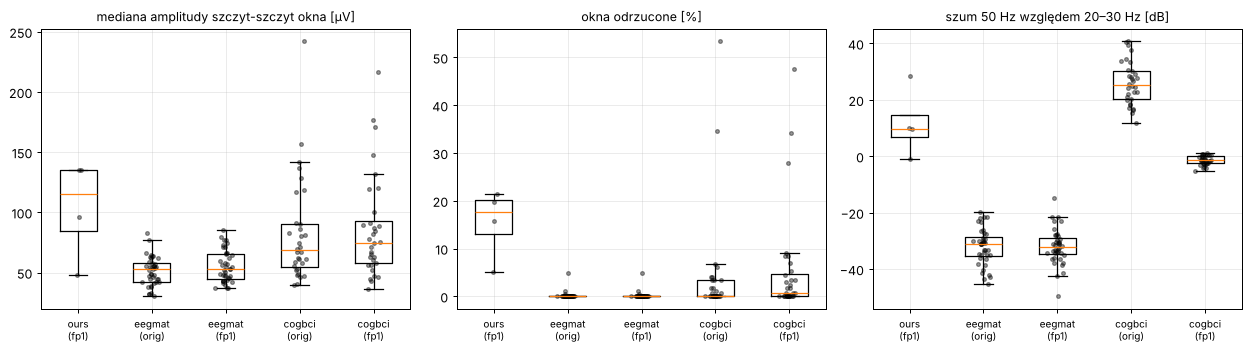

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
order = ["ours (fp1)", "eegmat (orig)", "eegmat (fp1)", "cogbci (orig)", "cogbci (fp1)"]
for ax, col, title in zip(axes, ["p2p_mediana_uV", "odrzucone_proc", "szum_50Hz_dB"],
                          ["mediana amplitudy szczyt-szczyt okna [µV]", "okna odrzucone [%]", "szum 50 Hz względem 20–30 Hz [dB]"]):
    data = [Q[Q.zrodlo == z][col].dropna().values for z in order]
    ax.boxplot(data, showfliers=False)
    ax.set_xticklabels([z.replace(" ", "\n") for z in order], fontsize=8)
    for i, d in enumerate(data):
        ax.plot(np.random.default_rng(0).normal(i + 1, 0.06, len(d)), d, ".", alpha=0.4, color="k")
    ax.set_title(title, fontsize=10)
plt.tight_layout(); plt.show()

## 5. Kształt widma: czy to ten sam sygnał?

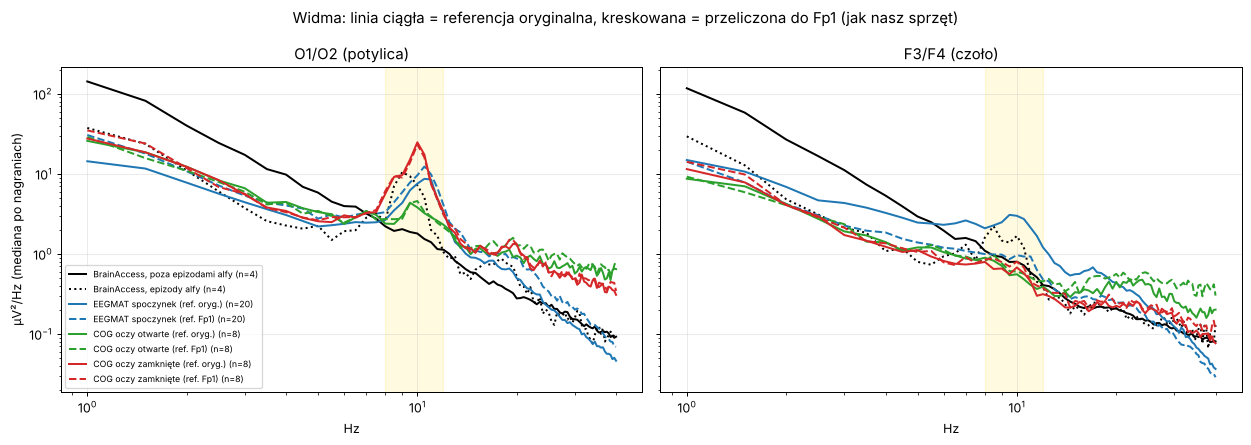

In [10]:
groups = {
    "BrainAccess, poza epizodami alfy": lambda s: s["dataset"] == "ours" and s["condition"] == "other",
    "BrainAccess, epizody alfy": lambda s: s["dataset"] == "ours" and s["condition"] == "alpha_episode",
    "EEGMAT spoczynek (ref. oryg.)": lambda s: s["dataset"] == "eegmat" and s["condition"] == "rest" and s["ref"] == "orig",
    "EEGMAT spoczynek (ref. Fp1)": lambda s: s["dataset"] == "eegmat" and s["condition"] == "rest" and s["ref"] == "fp1",
    "COG oczy otwarte (ref. oryg.)": lambda s: s["dataset"] == "cogbci" and s["condition"] == "eyes_open" and s["ref"] == "orig",
    "COG oczy otwarte (ref. Fp1)": lambda s: s["dataset"] == "cogbci" and s["condition"] == "eyes_open" and s["ref"] == "fp1",
    "COG oczy zamknięte (ref. oryg.)": lambda s: s["dataset"] == "cogbci" and s["condition"] == "eyes_closed" and s["ref"] == "orig",
    "COG oczy zamknięte (ref. Fp1)": lambda s: s["dataset"] == "cogbci" and s["condition"] == "eyes_closed" and s["ref"] == "fp1",
}
freqs = store[0]["freqs"]


def group_psd(sel, chans):
    """Per-recording median PSD over windows (averaged over chans), one row per recording."""
    rows = [np.median(s["psd"][:, chans].mean(1), axis=0) for s in store if sel(s) and len(s["psd"])]
    return np.array(rows)


styles = {"BrainAccess": ("k", "-"), "EEGMAT": ("tab:blue", "-"), "COG oczy otwarte": ("tab:green", "-"), "COG oczy zamknięte": ("tab:red", "-")}
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, chans, title in zip(axes, [[6, 7], [0, 1]], ["O1/O2 (potylica)", "F3/F4 (czoło)"]):
    for name, sel in groups.items():
        P = group_psd(sel, chans)
        if not len(P):
            continue
        color = next(c for k, (c, _) in styles.items() if name.startswith(k))
        ls = "--" if "Fp1" in name else "-"
        if name == "BrainAccess, epizody alfy":
            ls = ":"
        ax.loglog(freqs, np.median(P, 0), color=color, ls=ls, lw=1.6, label=f"{name} (n={len(P)})")
    ax.axvspan(8, 12, color="gold", alpha=0.12)
    ax.set_title(title); ax.set_xlabel("Hz")
axes[0].set_ylabel("µV²/Hz (mediana po nagraniach)")
axes[0].legend(fontsize=7)
plt.suptitle("Widma: linia ciągła = referencja oryginalna, kreskowana = przeliczona do Fp1 (jak nasz sprzęt)")
plt.tight_layout(); plt.show()

In [11]:
def spectral_slope(psd_row):
    m = ((freqs >= 2) & (freqs <= 6)) | ((freqs >= 14) & (freqs <= 35))
    return linregress(np.log10(freqs[m]), np.log10(psd_row[m])).slope


rows = []
for name, sel in groups.items():
    for chans, cname in (([6, 7], "O1/O2"), ([0, 1], "F3/F4")):
        P = group_psd(sel, chans)
        for r in P:
            rows.append(dict(grupa=name, kanaly=cname, nachylenie=spectral_slope(r)))
S = pd.DataFrame(rows)
S.groupby(["grupa", "kanaly"]).nachylenie.agg(["median", "count"]).round(2).unstack("kanaly")

median       count      
kanaly                            F3/F4 O1/O2 F3/F4 O1/O2
grupa                                                    
BrainAccess, epizody alfy         -1.21 -1.54     4     4
BrainAccess, poza epizodami alfy  -1.79 -2.00     4     4
COG oczy otwarte (ref. Fp1)       -1.16 -0.93     8     8
COG oczy otwarte (ref. oryg.)     -1.22 -1.16     8     8
COG oczy zamknięte (ref. Fp1)     -1.14 -1.00     8     8
COG oczy zamknięte (ref. oryg.)   -1.19 -1.03     8     8
EEGMAT spoczynek (ref. Fp1)       -1.38 -1.44    20    20
EEGMAT spoczynek (ref. oryg.)     -1.52 -1.56    20    20

## 6. Co robi referencja Fp1 z wskaźnikami Wachty

Dla każdego kontrastu liczymy efekt na poziomie osób: średnia z okien w warunku B minus A, potem standaryzowana różnica sparowana (*d*z = średnia różnic / odchylenie różnic). Przedział ufności 95% z bootstrapu po osobach. Porównujemy referencję oryginalną z przeliczoną do Fp1.

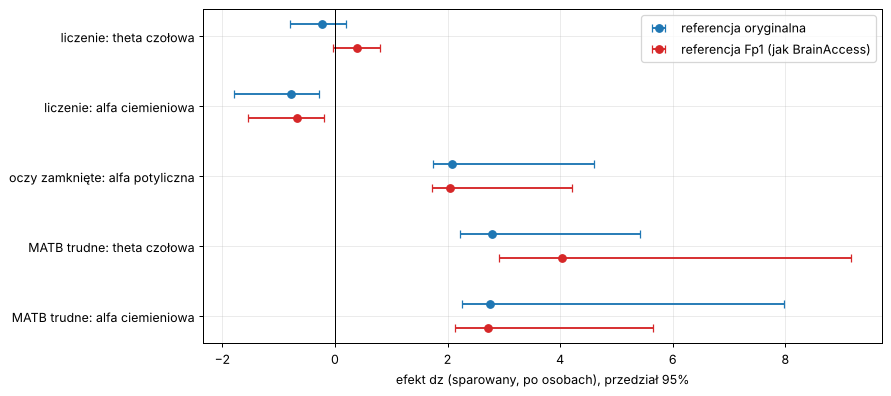

dz          lo          hi      
ref                               fp1  orig   fp1  orig   fp1  orig
kontrast                                                           
MATB trudne: alfa ciemieniowa    2.72  2.76  2.14  2.25  5.64  7.98
MATB trudne: theta czołowa       4.02  2.79  2.91  2.22  9.17  5.42
liczenie: alfa ciemieniowa      -0.67 -0.78 -1.54 -1.79 -0.20 -0.28
liczenie: theta czołowa          0.39 -0.23 -0.04 -0.79  0.80  0.20
oczy zamknięte: alfa potyliczna  2.04  2.09  1.72  1.74  4.21  4.60

In [12]:
contrasts = [
    ("EEGMAT", "eegmat", "rest", "task", "theta_front", "liczenie: theta czołowa"),
    ("EEGMAT", "eegmat", "rest", "task", "alpha_par", "liczenie: alfa ciemieniowa"),
    ("COG-BCI", "cogbci", "eyes_open", "eyes_closed", "alpha_occ", "oczy zamknięte: alfa potyliczna"),
    ("COG-BCI", "cogbci", "matb_easy", "matb_difficult", "theta_front", "MATB trudne: theta czołowa"),
    ("COG-BCI", "cogbci", "matb_easy", "matb_difficult", "alpha_par", "MATB trudne: alfa ciemieniowa"),
]
rng = np.random.default_rng(0)


def paired_d(df, a, b, col):
    m = df.groupby(["subject", "condition"])[col].mean().unstack()[[a, b]].dropna()
    diff = (m[b] - m[a]).values
    dz = diff.mean() / diff.std(ddof=1)
    boots = [(lambda s: s.mean() / s.std(ddof=1))(rng.choice(diff, len(diff))) for _ in range(2000)]
    return dz, np.percentile(boots, 2.5), np.percentile(boots, 97.5), len(diff)


rows = []
for _, ds, a, b, col, label in contrasts:
    for ref in ("orig", "fp1"):
        dz, lo, hi, n = paired_d(F[(F.dataset == ds) & (F.ref == ref)], a, b, col)
        rows.append(dict(kontrast=label, ref=ref, dz=dz, lo=lo, hi=hi, n=n))
E = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(10, 4.5))
y = np.arange(len(contrasts))
for k, (ref, color, off) in enumerate((("orig", "tab:blue", -0.17), ("fp1", "tab:red", 0.17))):
    e = E[E.ref == ref]
    ax.errorbar(e.dz, y + off, xerr=[e.dz - e.lo, e.hi - e.dz], fmt="o", color=color, capsize=3,
                label="referencja oryginalna" if ref == "orig" else "referencja Fp1 (jak BrainAccess)")
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(y, [c[5] for c in contrasts]); ax.invert_yaxis()
ax.set_xlabel("efekt dz (sparowany, po osobach), przedział 95%")
ax.legend(); plt.tight_layout(); plt.show()
E.round(2).pivot(index="kontrast", columns="ref", values=["dz", "lo", "hi"]).round(2)

### Dlaczego tak: korelacje między kanałami

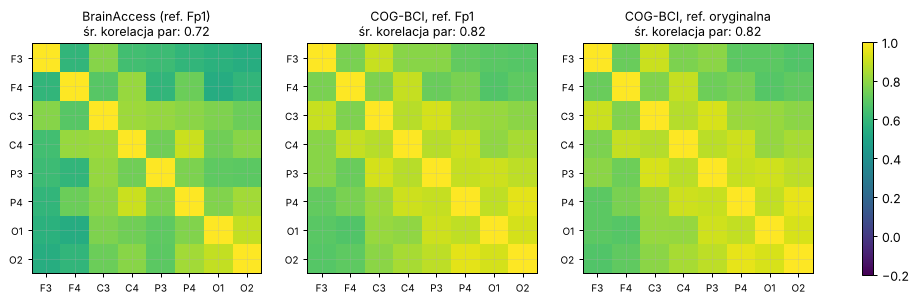

In [13]:
def pooled_corr(sel):
    cs = [s["corr"] for s in store if sel(s) and not np.isnan(s["corr"]).any()]
    return np.mean(cs, axis=0), len(cs)


panels = {
    "BrainAccess (ref. Fp1)": lambda s: s["dataset"] == "ours" and s["condition"] == "other",
    "COG-BCI, ref. Fp1": lambda s: s["dataset"] == "cogbci" and s["ref"] == "fp1",
    "COG-BCI, ref. oryginalna": lambda s: s["dataset"] == "cogbci" and s["ref"] == "orig",
}
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, (name, sel) in zip(axes, panels.items()):
    C, n = pooled_corr(sel)
    im = ax.imshow(C, vmin=-0.2, vmax=1, cmap="viridis")
    ax.set_xticks(range(8), OUR_CH, fontsize=8); ax.set_yticks(range(8), OUR_CH, fontsize=8)
    off = C[~np.eye(8, dtype=bool)]
    ax.set_title(f"{name}\nśr. korelacja par: {off.mean():.2f}", fontsize=10)
plt.colorbar(im, ax=axes, shrink=0.8)
plt.show()

## 7. Alfa w naszych epizodach a alfa przy zamkniętych oczach w COG-BCI

Wyrazistość alfy to log10 stosunku mocy 8–12 Hz do sąsiednich pasm (5–7 i 14–16 Hz), na O1/O2. Wartość 0 oznacza brak piku, im wyżej, tym wyraźniejszy pik.

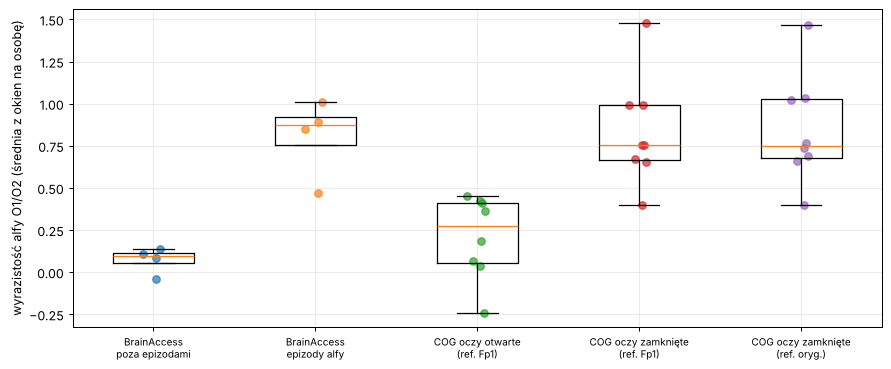

,mediana,n osób
BrainAccess poza epizodami,0.10,4.0
BrainAccess epizody alfy,0.87,4.0
COG oczy otwarte (ref. Fp1),0.28,8.0
COG oczy zamknięte (ref. Fp1),0.75,8.0
COG oczy zamknięte (ref. oryg.),0.75,8.0


In [14]:
order = [
    ("BrainAccess\npoza epizodami", lambda s: s["dataset"] == "ours" and s["condition"] == "other"),
    ("BrainAccess\nepizody alfy", lambda s: s["dataset"] == "ours" and s["condition"] == "alpha_episode"),
    ("COG oczy otwarte\n(ref. Fp1)", lambda s: s["dataset"] == "cogbci" and s["condition"] == "eyes_open" and s["ref"] == "fp1"),
    ("COG oczy zamknięte\n(ref. Fp1)", lambda s: s["dataset"] == "cogbci" and s["condition"] == "eyes_closed" and s["ref"] == "fp1"),
    ("COG oczy zamknięte\n(ref. oryg.)", lambda s: s["dataset"] == "cogbci" and s["condition"] == "eyes_closed" and s["ref"] == "orig"),
]
fig, ax = plt.subplots(figsize=(10, 4.2))
vals = []
for i, (name, sel) in enumerate(order):
    per = [s["feat"].alpha_prom.mean() for s in store if sel(s) and len(s["feat"])]
    vals.append(per)
    ax.plot(np.random.default_rng(1).normal(i + 1, 0.05, len(per)), per, "o", alpha=0.7)
ax.boxplot(vals, showfliers=False)
ax.set_xticklabels([o[0] for o in order], fontsize=8)
ax.set_ylabel("wyrazistość alfy O1/O2 (średnia z okien na osobę)")
plt.tight_layout(); plt.show()
pd.DataFrame({o[0].replace("\n", " "): [np.median(v), len(v)] for o, v in zip(order, vals)}, index=["mediana", "n osób"]).round(2).T

## Wnioski

1. **Nasze dane są wyraźnie bardziej zaszumione.** Mediana amplitudy okna to 115 µV wobec 53 µV (EEGMAT) i 68–75 µV (COG-BCI). Odrzucamy 17,7% okien (zakres 5–21% po osobach), a w zbiorach laboratoryjnych ok. 0–1%.
2. **Widmo ma inny kształt.** BrainAccess ma kilka razy więcej mocy poniżej 5 Hz (dryf, ruch, mrugnięcia) i mniej mocy powyżej 25 Hz niż COG-BCI. Nachylenie widma na O1/O2 wynosi u nas −2,0, a w zbiorach laboratoryjnych od −0,9 do −1,6. Progi bezwzględne z danych publicznych nie przenoszą się na nasz sprzęt, więc kalibracja na osobę jest konieczna. Theta (4–7 Hz) leży na stromej części widma, więc prawdopodobnie jest bardziej narażona na wyciek mocy z dryfu niż alfa.
3. **Szum sieciowy zależy od referencji.** W COG-BCI z oryginalną referencją jest +25 dB, a po przeliczeniu do Fp1 spada do −1 dB, bo napięcie sieciowe jest wspólne dla wszystkich elektrod i odejmuje się razem z referencją. U nas mediana to +10 dB (od −1 do +29 dB zależnie od sesji). Referencja na czole nie wystarcza więc, gdy kontakt elektrody odniesienia jest słaby albo środowisko głośne. EEGMAT ma sprzętowy filtr 50 Hz (−31 dB), więc go tu nie porównujemy.
4. **Referencja Fp1 prawie nie zmienia wskaźników.** Widma i efekty są podobne w obu wariantach, a przedziały ufności się pokrywają. Oczy zamknięte → alfa potyliczna: dz = 2,1 (oryginalna) i 2,0 (Fp1). Liczenie → alfa ciemieniowa: −0,8 i −0,7. Liczenie → theta czołowa: −0,2 i +0,4, w obu wariantach nie różni się od zera. Brak stabilnej theta czołowej przy liczeniu nie wynika więc z referencji.
5. **Uwaga do założeń Wachty: w trudnym zadaniu MATB alfa ciemieniowa rośnie, a nie spada** (dz ≈ +2,7 przy obu referencjach), razem z theta czołową (dz 2,8 i 4,0). Przy liczeniu w pamięci alfa ciemieniowa spada zgodnie z założeniem. Reguła „przeciążony = theta w górę, alfa w dół” jest więc potwierdzona w jednym z dwóch zadań. Możliwe przyczyny, których nie sprawdzałem: kolejność zadań w sesji (narastające zmęczenie) i ogólny wzrost mocy przy ruchach oczu i rąk w MATB. Próba to 8 osób, a przedziały są szerokie.
6. **Alfa w naszych epizodach** ma wyrazistość 0,87 wobec 0,75 dla zamkniętych oczu w COG-BCI, a poza epizodami 0,10 wobec 0,28 przy otwartych oczach. Nasza wartość jest wyższa głównie dlatego, że epizody wybraliśmy właśnie po wyrazistości alfy, więc **tego nie wolno czytać jako lepszej jakości sygnału**. Pewne jest tylko tyle, że sygnał z suchych elektrod pozwala wyłapać wyraźny pik alfy. Etykiety protokołu potwierdziły później, że wszystkie te epizody to faktycznie zamknięte oczy (notebook 01, sekcja 6).
7. **Korelacje między kanałami** są niższe u nas (średnio 0,72) niż w COG-BCI (0,82), co zgadza się z różną jakością kontaktu poszczególnych elektrod suchych.

**Co z tego dla projektu:** (a) kalibracja na osobę i brak progów z danych publicznych, (b) odrzucanie artefaktów jest obowiązkowe, (c) alfa potyliczna to najpewniejszy wskaźnik (dz ≈ 2 przy obu referencjach i widoczna w naszych nagraniach), (d) przeciążenie wymaga dalszych badań. Notebook 03 sprawdził regułę na naszym bloku liczenia w pamięci (`math`) z prawdziwymi etykietami: nie zapaliła się ani razu.